In [1]:
'''Implement LIME (Local Interpretable Model-agnostic Explanations) to provide instance-level explanations of model predictions, supporting admissions officers in interpreting model outputs.'''

'Implement LIME (Local Interpretable Model-agnostic Explanations) to provide instance-level explanations of model predictions, supporting admissions officers in interpreting model outputs.'

In [2]:
# import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from lime.lime_tabular import LimeTabularExplainer

df = pd.read_csv('Adm.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# prepare features and train test split
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training samples:', len(X_train), 'Testing samples:', len(X_test))

Training samples: 800 Testing samples: 200


In [4]:
# train random forest model and evaluate metrics
from sklearn.metrics import mean_squared_error, r2_score

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('R2 Score:', round(r2_score(y_test, y_pred), 3))
print('Mean Squared Error:', round(mean_squared_error(y_test, y_pred), 4))

R2 Score: 0.908
Mean Squared Error: 0.0009


In [5]:
# initialize lime tabular explainer
predict_fn = lambda x: model.predict(pd.DataFrame(x, columns=features))

explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=features,
    mode='regression',
    random_state=42
)

In [6]:
# define admission criteria and identify applicant profiles
admit_idx = y_test.argmax()
reject_idx = y_test.argmin()
border_idx = (y_test - 0.70).abs().argmin()

print('Admitted applicant index:', admit_idx, 'Actual chance:', round(y_test.iloc[admit_idx], 3))
print('Borderline applicant index:', border_idx, 'Actual chance:', round(y_test.iloc[border_idx], 3))
print('Rejected applicant index:', reject_idx, 'Actual chance:', round(y_test.iloc[reject_idx], 3))

Admitted applicant index: 194 Actual chance: 0.98
Borderline applicant index: 64 Actual chance: 0.7
Rejected applicant index: 33 Actual chance: 0.46


Predicted Chance of Admit: 0.958


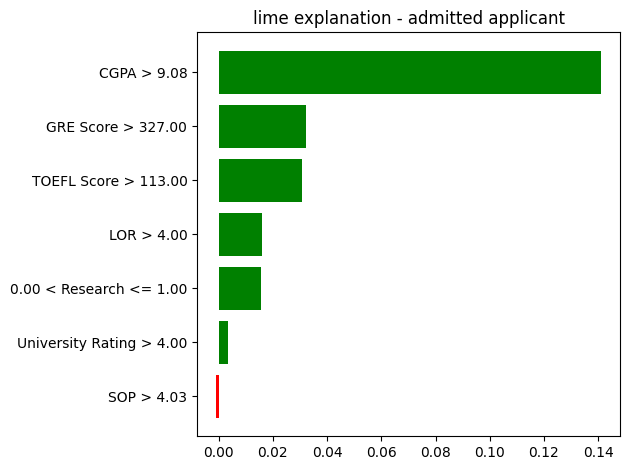

In [7]:
# explain high chance applicant decision and plot
inst_admit = X_test.iloc[admit_idx]
pred_admit = predict_fn(inst_admit.values.reshape(1, -1))[0]
print('Predicted Chance of Admit:', round(pred_admit, 3))

exp_admit = explainer.explain_instance(inst_admit.values, predict_fn, num_features=7)
exp_admit.as_pyplot_figure()
plt.title('lime explanation - admitted applicant')
plt.tight_layout()
plt.show()

Predicted Chance of Admit: 0.692


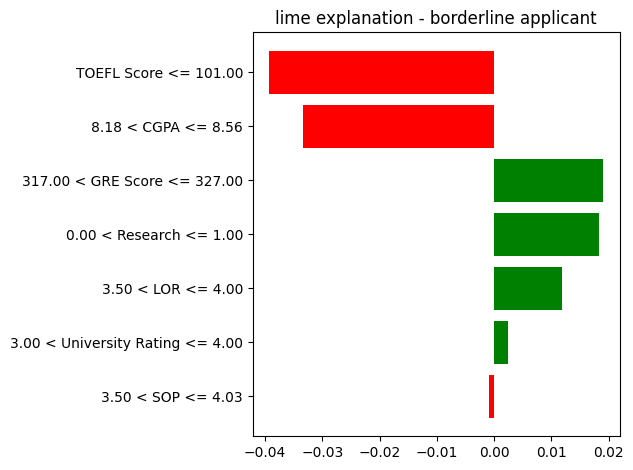

In [8]:
# explain borderline applicant decision and plot
inst_border = X_test.iloc[border_idx]
pred_border = predict_fn(inst_border.values.reshape(1, -1))[0]
print('Predicted Chance of Admit:', round(pred_border, 3))

exp_border = explainer.explain_instance(inst_border.values, predict_fn, num_features=7)
exp_border.as_pyplot_figure()
plt.title('lime explanation - borderline applicant')
plt.tight_layout()
plt.show()

Predicted Chance of Admit: 0.52


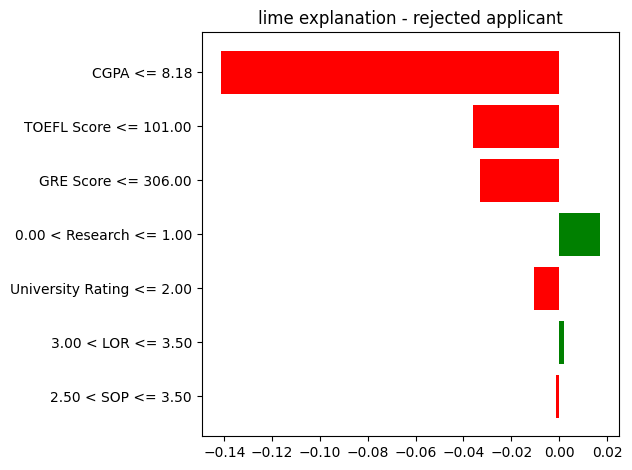

In [9]:
# explain low chance applicant decision and plot
inst_reject = X_test.iloc[reject_idx]
pred_reject = predict_fn(inst_reject.values.reshape(1, -1))[0]
print('Predicted Chance of Admit:', round(pred_reject, 3))

exp_reject = explainer.explain_instance(inst_reject.values, predict_fn, num_features=7)
exp_reject.as_pyplot_figure()
plt.title('lime explanation - rejected applicant')
plt.tight_layout()
plt.show()

In [10]:
# summarize lime criteria weights for admissions decision
summary_df = pd.DataFrame({
    'Admitted Applicant Criteria': [f'{c}: {round(w, 3)}' for c, w in exp_admit.as_list()],
    'Borderline Applicant Criteria': [f'{c}: {round(w, 3)}' for c, w in exp_border.as_list()],
    'Rejected Applicant Criteria': [f'{c}: {round(w, 3)}' for c, w in exp_reject.as_list()]
})
summary_df

,Admitted Applicant Criteria,Borderline Applicant Criteria,Rejected Applicant Criteria
0,CGPA > 9.08: 0.141,TOEFL Score <= 101.00: -0.039,CGPA <= 8.18: -0.141
1,GRE Score > 327.00: 0.032,8.18 < CGPA <= 8.56: -0.033,TOEFL Score <= 101.00: -0.036
2,TOEFL Score > 113.00: 0.031,317.00 < GRE Score <= 327.00: 0.019,GRE Score <= 306.00: -0.033
3,LOR > 4.00: 0.016,0.00 < Research <= 1.00: 0.018,0.00 < Research <= 1.00: 0.017
4,0.00 < Research <= 1.00: 0.016,3.50 < LOR <= 4.00: 0.012,University Rating <= 2.00: -0.011
5,University Rating > 4.00: 0.003,3.00 < University Rating <= 4.00: 0.002,3.00 < LOR <= 3.50: 0.002
6,SOP > 4.03: -0.001,3.50 < SOP <= 4.03: -0.001,2.50 < SOP <= 3.50: -0.001
